In [1]:
import pandas as pd
print("Wszystko działa!")

Wszystko działa!


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ustawienie ładnego stylu dla wykresów
sns.set_theme(style="whitegrid")

# 1. Wczytujemy nasz plik CSV
df = pd.read_csv('Border_Crossing_Entry_Data.csv')

# 2. Zamieniamy kolumnę z datą na odpowiedni format, żeby Python rozumiał lata i miesiące
#df['Date'] = pd.to_datetime(df['Date'])

# Poprawa WARNING.
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y %I:%M:%S %p', errors='coerce')

# 3. Wyświetlamy podstawowe informacje o tabeli
print(f"Pomyślnie załadowano bazę! Mamy {df.shape[0]} wierszy i {df.shape[1]} kolumn.\n")
print("Oto pierwsze 5 wierszy:")
df.head()

Pomyślnie załadowano bazę! Mamy 346733 wierszy i 8 kolumn.

Oto pierwsze 5 wierszy:


,Port Name,State,Port Code,Border,Date,Measure,Value,Location
0,Calexico East,California,2507,US-Mexico Border,2019-03-01,Trucks,34447,POINT (-115.48433000000001 32.67524)
1,Van Buren,Maine,108,US-Canada Border,2019-03-01,Rail Containers Full,428,POINT (-67.94271 47.16207)
2,Otay Mesa,California,2506,US-Mexico Border,2019-03-01,Trucks,81217,POINT (-117.05333 32.57333)
3,Nogales,Arizona,2604,US-Mexico Border,2019-03-01,Trains,62,POINT (-110.93361 31.340279999999996)
4,Trout River,New York,715,US-Canada Border,2019-03-01,Personal Vehicle Passengers,16377,POINT (-73.44253 44.990010000000005)


In [10]:
# Sprawdzamy, ile jest pustych (brakujących) pól w każdej kolumnie
print("Liczba brakujących wartości (NaN) w kolumnach:")
print(df.isnull().sum())

# Sprawdzamy, czy w kategorycznych kolumnach występuje słowo 'Unknown'
print("\nCzy w kolumnie Port Name jest 'Unknown'?:", 'Unknown' in df['Port Name'].values)
print("Czy w kolumnie State jest 'Unknown'?:", 'Unknown' in df['State'].values)

Liczba brakujących wartości (NaN) w kolumnach:
Port Name    0
State        0
Port Code    0
Border       0
Date         0
Measure      0
Value        0
Location     0
dtype: int64

Czy w kolumnie Port Name jest 'Unknown'?: False
Czy w kolumnie State jest 'Unknown'?: False


###  Kontrola jakości danych:
Zbiór danych został zweryfikowany pod kątem braków informacyjnych. Wszystkie kolumny posiadają 100% kompletnych wpisów (brak wartości typu `NaN` oraz etykiet typu `Unknown`). Dane są w pełni gotowe do analizy biznesowej.

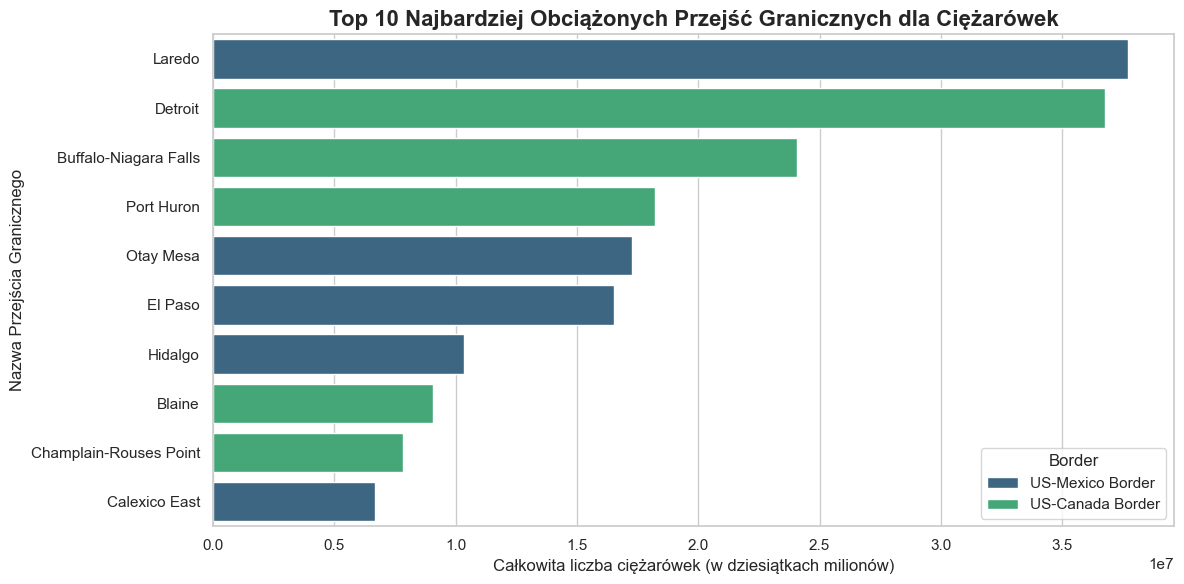

In [3]:
# 1. Filtrujemy dane - interesują nas tylko ciężarówki (Trucks)
df_trucks = df[df['Measure'] == 'Trucks'].copy()

# 2. Agregujemy (sumujemy) liczbę ciężarówek dla każdego portu i granicy
top_ports = df_trucks.groupby(['Port Name', 'Border'])['Value'].sum().reset_index()

# 3. Sortujemy od największego ruchu i bierzemy 10 pierwszych
top_10_ports = top_ports.sort_values(by='Value', ascending=False).head(10)

# 4. Tworzymy wykres
plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_10_ports, 
    x='Value', 
    y='Port Name', 
    hue='Border', 
    palette='viridis'
)

# Dodajemy tytuły i opisy osi
plt.title('Top 10 Najbardziej Obciążonych Przejść Granicznych dla Ciężarówek', fontsize=16, fontweight='bold')
plt.xlabel('Całkowita liczba ciężarówek (w dziesiątkach milionów)', fontsize=12)
plt.ylabel('Nazwa Przejścia Granicznego', fontsize=12)
plt.tight_layout()

# Pokazujemy wykres bezpośrednio w VS Code
plt.show()

### Wnioski z analizy Top 10 Przejść Granicznych:

1. **Główni liderzy ruchu:** Absolutnymi centrami logistycznymi są przejścia **Laredo** (na granicy z Meksykiem) oraz **Detroit** (na granicy z Kanadą). To tam firma transportowa musi liczyć się z największym ryzykiem zatorów i najdłuższym czasem odprawy.
2. **Dysproporcja na granicy południowej:** Na granicy z Meksykiem ruch skupia się drastycznie na kilku potężnych punktach (Laredo, Otay Mesa, El Paso). Z kolei na granicy z Kanadą ruch rozkłada się nieco bardziej równomiernie (Detroit, Buffalo-Niagara Falls, Port Huron).
3. **Rekomendacja dla Stakeholdera:** Jeśli firma planuje transport w rejonie Teksasu (Laredo) lub Michigan (Detroit), powinna rozważyć alternatywne, mniej obciążone przejścia w sąsiednich regionach lub planować przekraczanie granicy w godzinach mniejszego natężenia ruchu, aby zoptymalizować koszty paliwa i czasu pracy kierowców.

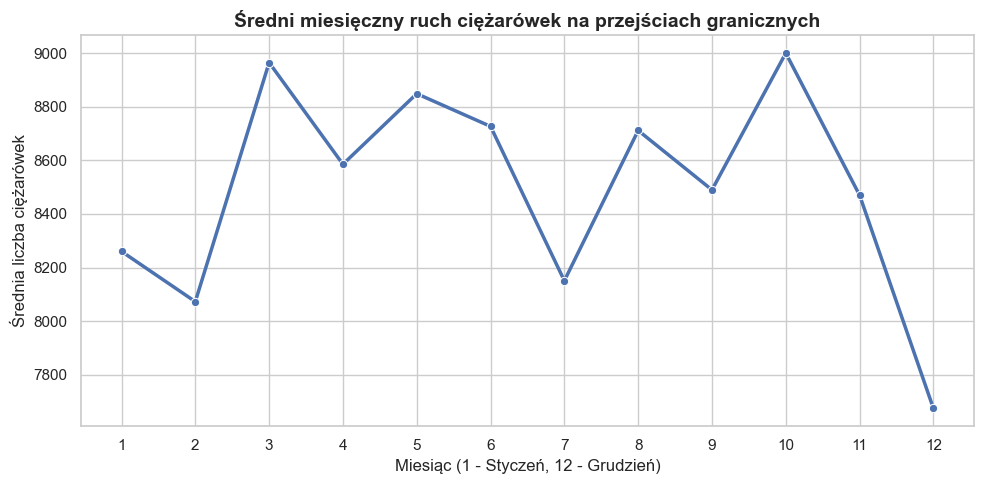

In [4]:
# 1. Wyciągamy miesiąc z naszej daty
df_trucks['Month'] = df_trucks['Date'].dt.month

# 2. Agregujemy średnią liczbę ciężarówek per miesiąc
monthly_traffic = df_trucks.groupby('Month')['Value'].mean().reset_index()

# 3. Tworzymy wykres liniowy
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=monthly_traffic, 
    x='Month', 
    y='Value', 
    marker='o', 
    linewidth=2.5, 
    color='b'
)

# Konfiguracja osi i tytułów
plt.title('Średni miesięczny ruch ciężarówek na przejściach granicznych', fontsize=14, fontweight='bold')
plt.xlabel('Miesiąc (1 - Styczeń, 12 - Grudzień)', fontsize=12)
plt.ylabel('Średnia liczba ciężarówek', fontsize=12)
plt.xticks(range(1, 13)) # Wymuszamy pokazanie wszystkich miesięcy od 1 do 12
plt.tight_layout()
plt.show()

###  Wnioski z analizy sezonowości (Ruch w ciągu roku):

1. **Zimowy dołek (Styczeń - Luty):** Na początku roku ruch drastycznie spada. Styczeń i luty to momenty, w których na granicach jest najluźniej. 
   * *Rekomendacja:* To idealny moment dla firmy na planowanie przeglądów technicznych floty, serwisowanie ciężarówek czy urlopy kierowców, ponieważ zapotrzebowanie na transport jest wtedy najniższe.
2. **Wiosenny i jesienny szczyt (Marzec oraz Październik):** Na wykresie widzimy dwa potężne skoki – marzec (piki przedświąteczne/wiosenne zatowarowanie) oraz absolutny rekord w październiku (przygotowania magazynów do gorącego okresu przedświątecznego i Black Friday).
   * *Rekomendacja:* W marcu i październiku firma musi przygotować się na maksymalną przepustowość. Czas oczekiwania na granicach drastycznie wzrośnie, więc należy doliczyć dodatkowe godziny (lub dni) do czasu dostawy, aby uniknąć kar umownych za opóźnienia.
3. **Grudniowy zjazd:** W grudniu ruch gwałtownie spada do najniższego poziomu w roku (zamknięcia budżetowe, święta, przerwy noworoczne w fabrykach).

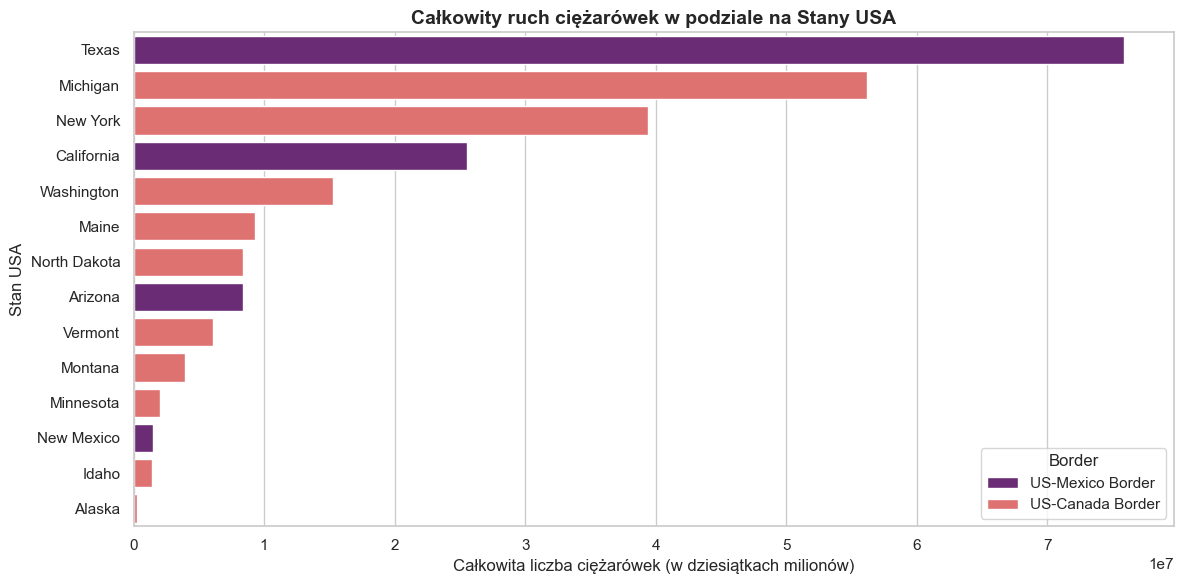

In [5]:
# 1. Agregujemy (sumujemy) ruch ciężarówek dla każdego stanu
state_traffic = df_trucks.groupby(['State', 'Border'])['Value'].sum().reset_index()

# 2. Sortujemy od stanu z największym ruchem
state_traffic = state_traffic.sort_values(by='Value', ascending=False)

# 3. Tworzymy wykres słupkowy
plt.figure(figsize=(12, 6))
sns.barplot(
    data=state_traffic, 
    x='Value', 
    y='State', 
    hue='Border', 
    palette='magma'
)

# Konfiguracja opisów
plt.title('Całkowity ruch ciężarówek w podziale na Stany USA', fontsize=14, fontweight='bold')
plt.xlabel('Całkowita liczba ciężarówek (w dziesiątkach milionów)', fontsize=12)
plt.ylabel('Stan USA', fontsize=12)
plt.tight_layout()
plt.show()

###  Wnioski z analizy geograficznej (Stany USA):

1. **Teksas absolutnym liderem południa:** Stan **Texas** obsługuje gigantyczną część całego ruchu towarowego z Meksykiem. Dla firmy transportowej oznacza to, że infrastruktura logistyczna, bazy przeładunkowe oraz znajomość przepisów celnych w Teksasie są kluczowe dla stabilności operacyjnej.
2. **Michigan i Nowy Jork centrami północy:** Na granicy z Kanadą najważniejszymi węzłami są stany **Michigan** (gdzie leży potężny port Detroit) oraz **New York** (obsługujący rejon Buffalo). To tam skupia się wymiana handlowa z Kanadą.
3. **Mniej obciążone regiony jako szlaki alternatywne:** Stany takie jak New Mexico (na południu) czy Idaho, Montana, Vermont (na północy) generują minimalny ruch ciężarowy. 
   * *Rekomendacja:* W przypadku kryzysów (strajki celników, blokady dróg, załamania pogodowe w głównych węzłach), stany o mniejszym natężeniu ruchu mogą posłużyć jako doskonałe, awaryjne szlaki transportowe dla ładunków o najwyższym priorytecie czasowym.